# Seminar 6 · Score matching and Langevin dynamics

**Deep Generative Models · MIPT / ШАД (YSDA) · 29 October 2026**

Adapted from the previous semester’s score matching and denoising seminar. The original sequence of topics is preserved.

[Part 1 · Score matching](seminar6.ipynb) · [Part 2 · NCSN](ncsn.ipynb) · [Part 3 · Denoising model](denoising_model.ipynb)

**Route:** score → denoising target → Langevin dynamics → several noise scales → code.

## Score matching

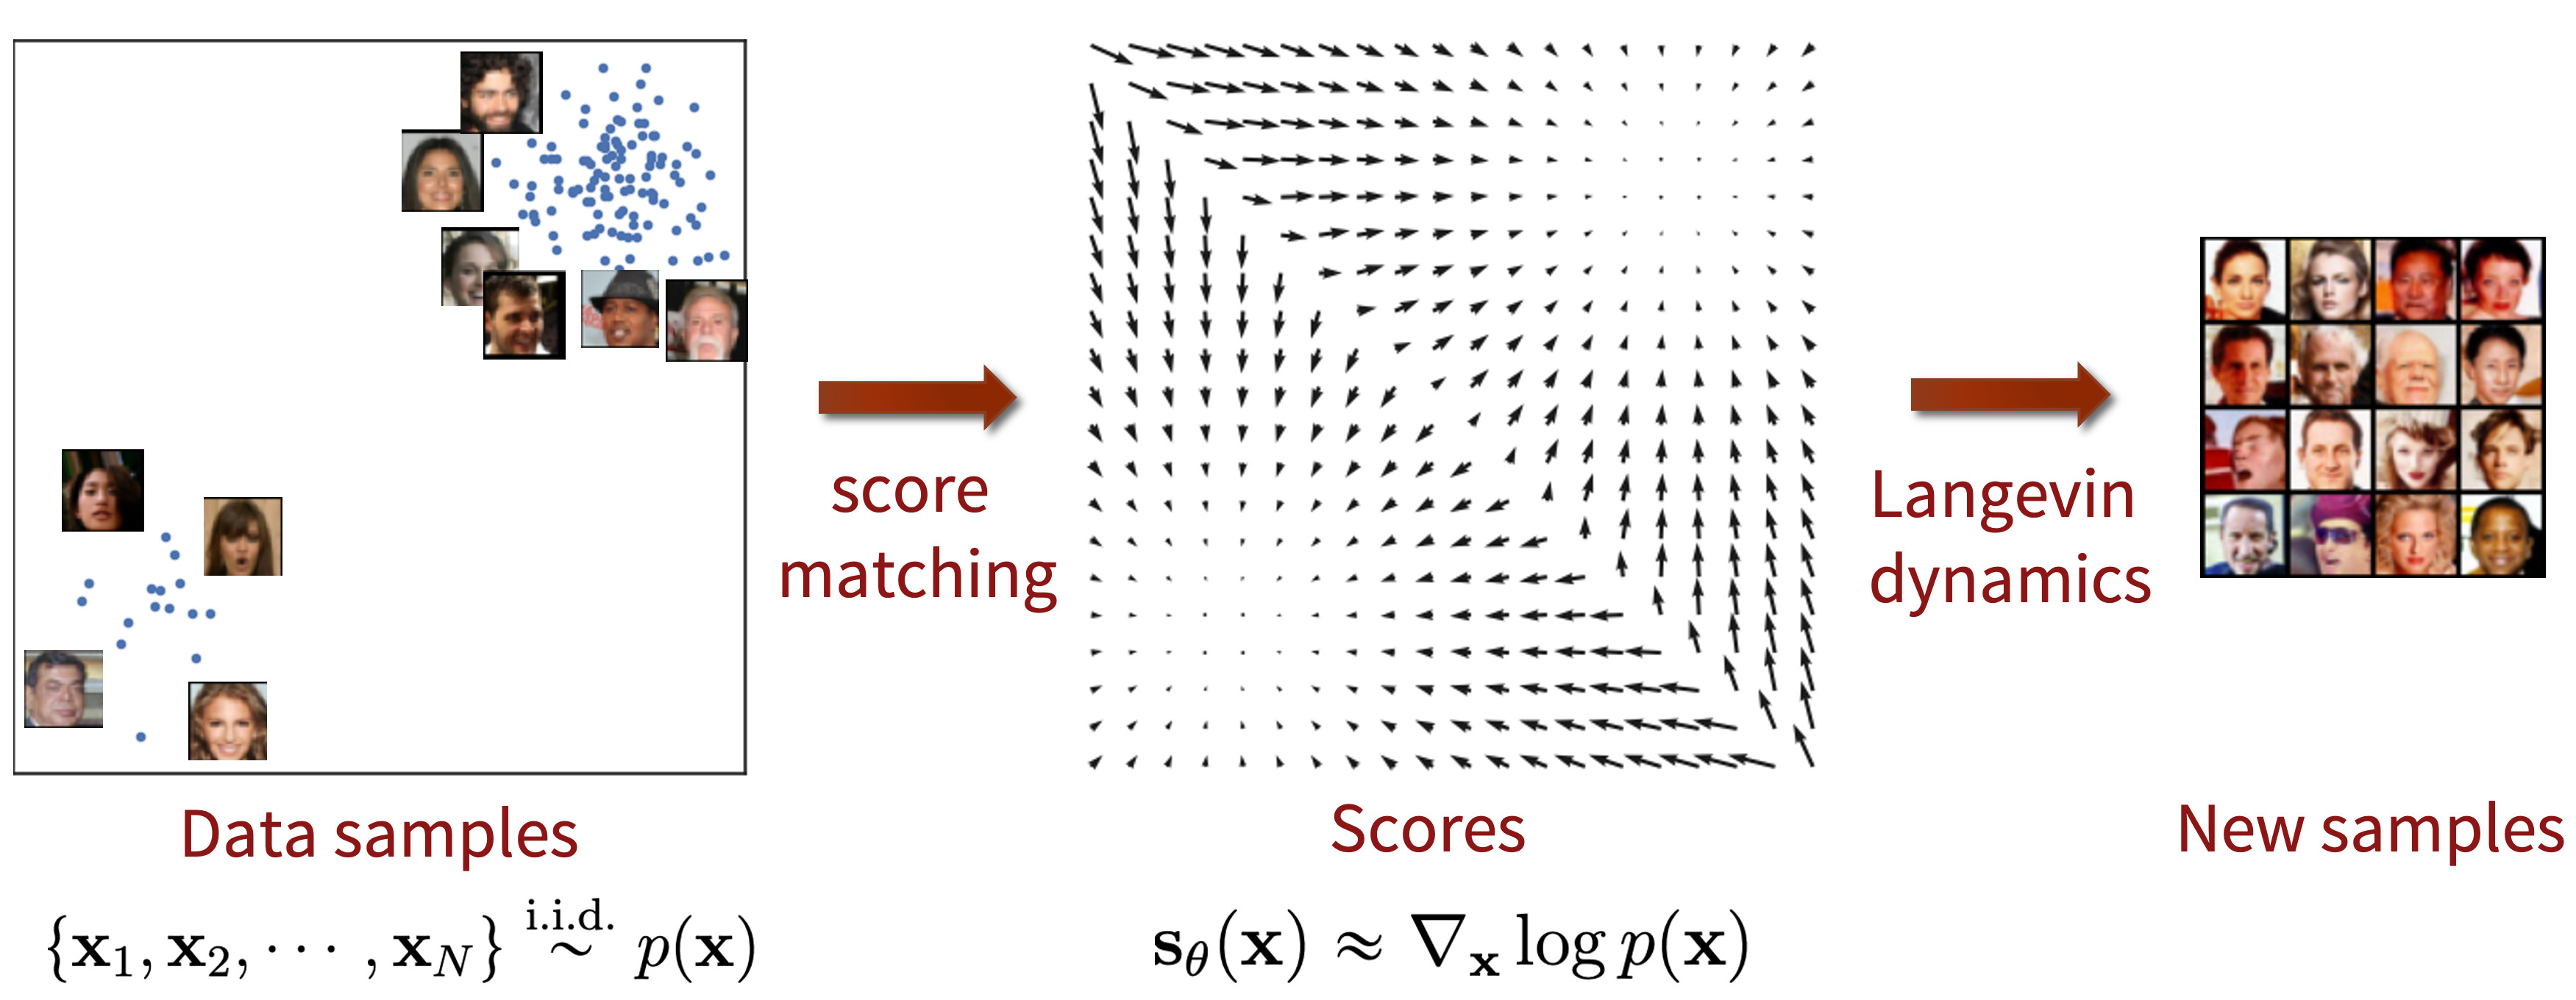

The **score** is a vector field, $\nabla_x\log p_{data}(x)$, with the same dimension as $x$.

$$\mathcal{L}_{SM}(\theta)=\frac12\mathbb{E}_{x\sim p_{data}}\|s_\theta(x)-\nabla_x\log p_{data}(x)\|_2^2.$$

**Takeaway.** Learn a direction in data space; sampling will repeatedly use that direction.

Source: [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600).

**Problem:** the data density and its score are unknown. We observe samples, so we need a target that can be computed from samples.

## Denoising score matching

For $y=x+\sigma\epsilon$, with $\epsilon\sim\mathcal{N}(0,I)$, define the **noisy data distribution**
$$q_\sigma(y)=\int p_{data}(x)\,q_\sigma(y\mid x)\,dx,\qquad q_\sigma(y\mid x)=\mathcal{N}(y;x,\sigma^2I).$$
The conditional Gaussian gives an explicit target:
$$\nabla_y\log q_\sigma(y\mid x)=-\frac{y-x}{\sigma^2}=-\frac{\epsilon}{\sigma}.$$

$$\mathcal{L}_{DSM}=\frac12\mathbb{E}_{x,\epsilon}\left\|s_\theta(x+\sigma\epsilon,\sigma)+\frac{\epsilon}{\sigma}\right\|^2
=\mathcal{L}_{SM}(q_\sigma)+C,$$
where $C$ is independent of $\theta$. The identity uses
$\mathbb{E}[\nabla_y\log q_\sigma(y\mid x)\mid y]=\nabla_y\log q_\sigma(y)$.

**Takeaway.** The per-example target is a conditional score; its conditional expectation is the marginal score we need for sampling.

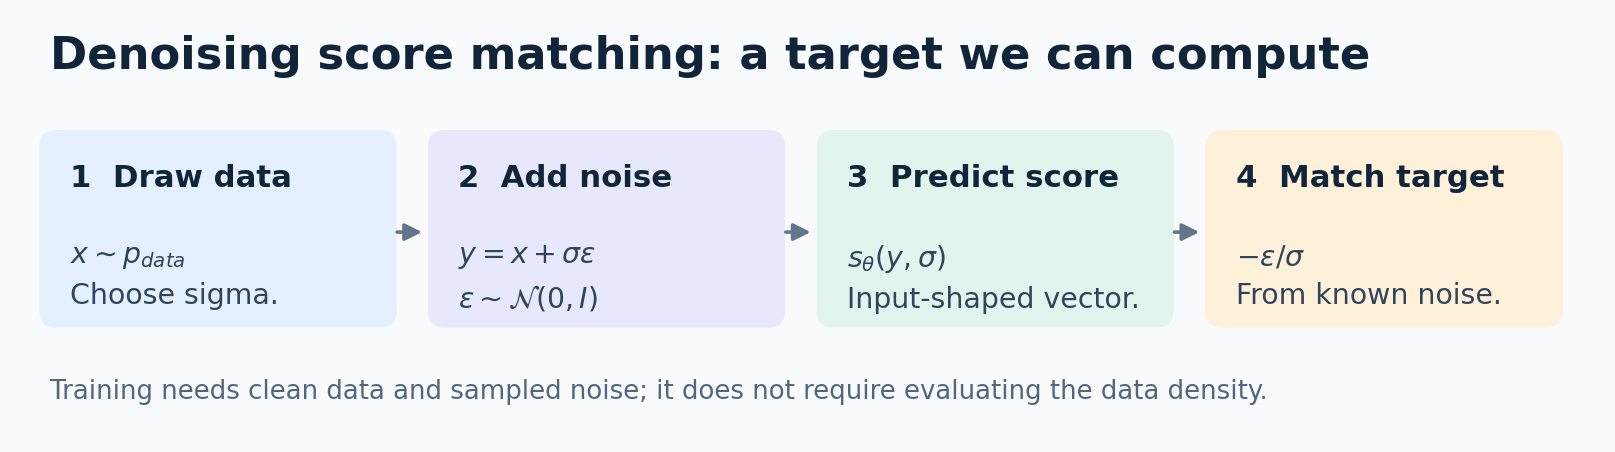

### Sampling (Langevin dynamics)

$$x_{k+1}=x_k+\frac{\eta}{2}s_\theta(x_k,\sigma)+\sqrt{\eta}\,\epsilon_k,\qquad\epsilon_k\sim\mathcal{N}(0,I).$$

Evaluate the score at the **current** point $x_k$. The drift moves toward higher log-density; the random term permits exploration. Finite steps introduce discretization error and may mix slowly.

**Question.** If we remove the random term, are we still trying to sample the whole distribution?

**Takeaway.** This is stochastic sampling, not simply finding a density maximum.

## Question 1 · Which noise scale should we choose?

With **small** $\sigma$ the problem comes from **the manifold hypothesis**:

> Real-world data tend to concentrate on a *low dimensional manifolds* embedded in a *high dimensional space*. 

The key challenge is the fact that the estimated score functions are inaccurate in low density regions, where few data points are available for computing the score matching objective.
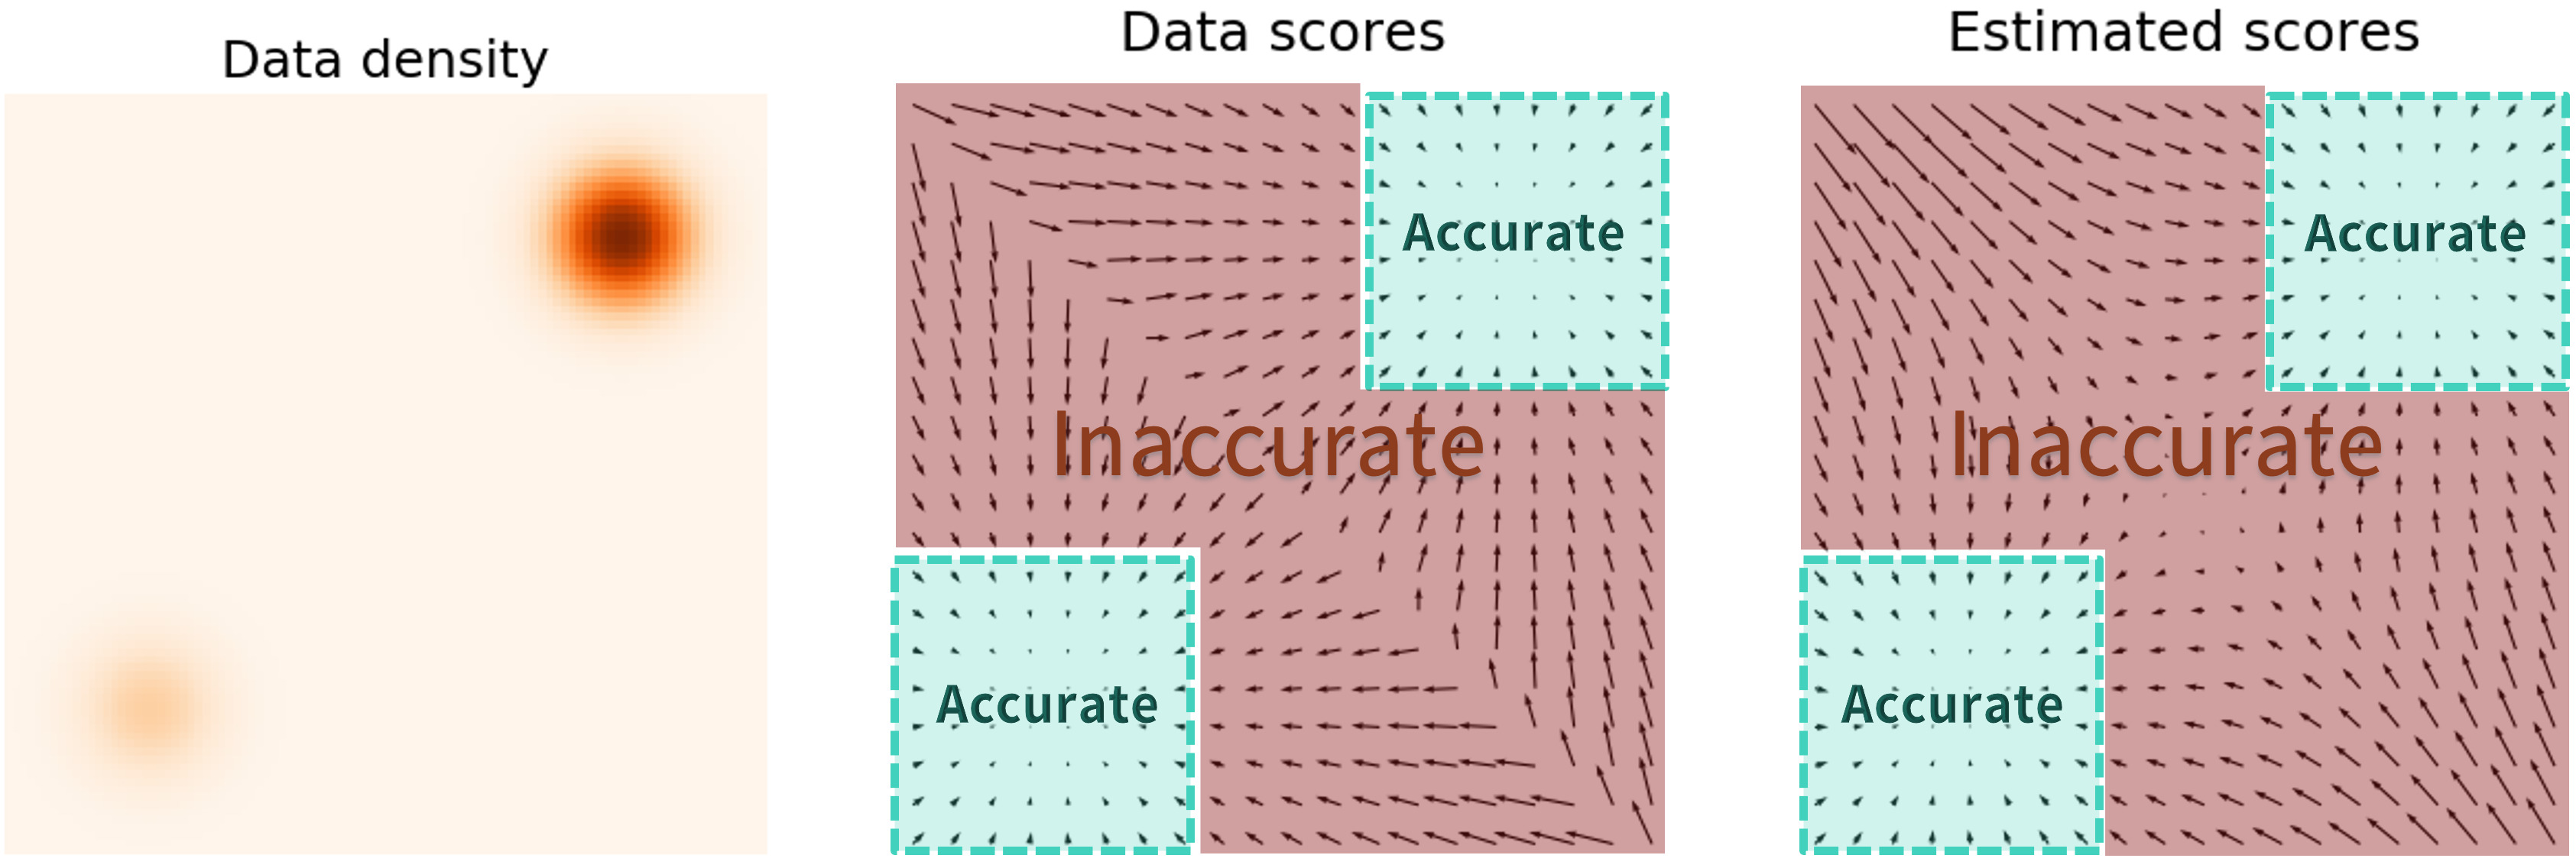

Source: [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600).

When the noise magnitude is sufficiently large, it can populate low data density regions to improve the accuracy of estimated scores.
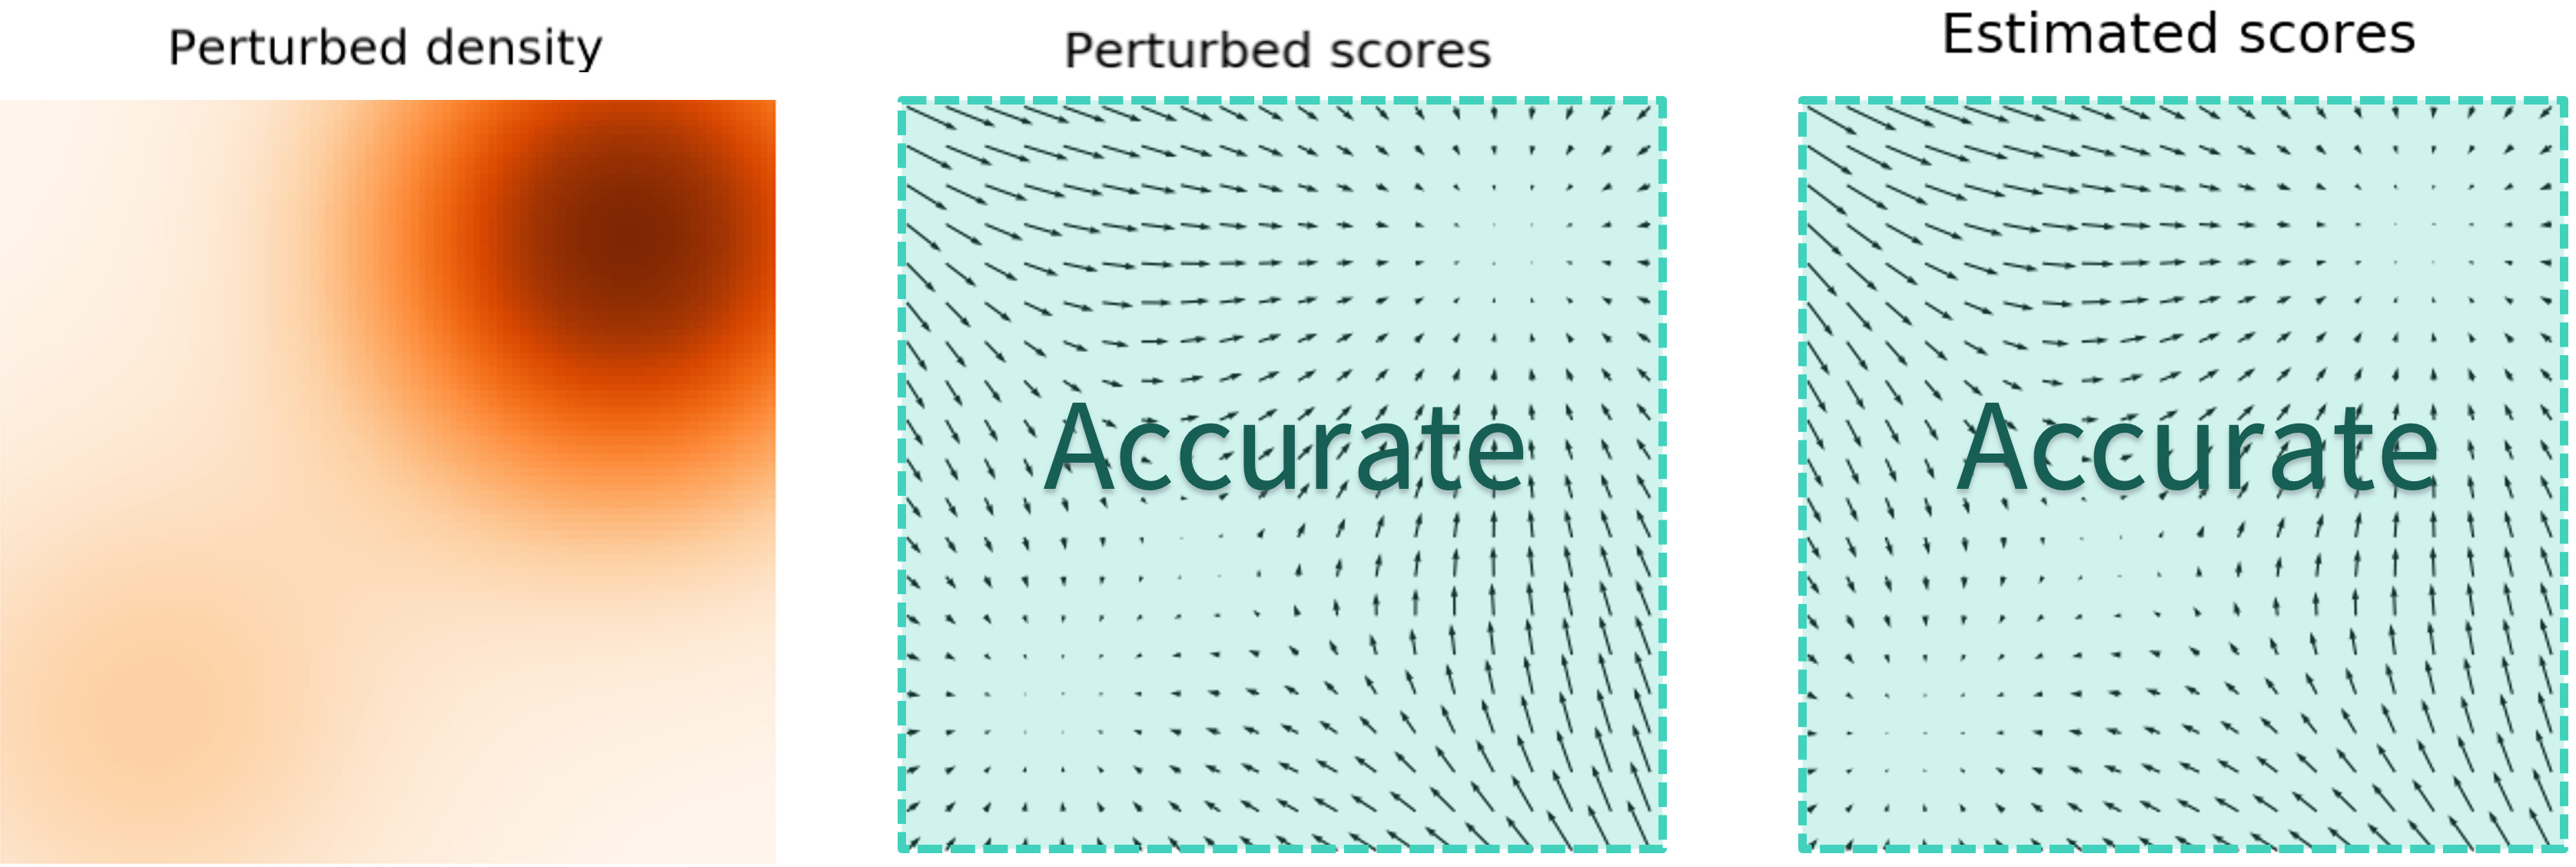

**Tradeoff.** Large noise improves coverage but blurs structure; a single noise scale must compromise.

Source: [Song & Ermon, 2019](https://arxiv.org/abs/1907.05600).

## Question 2 · How do we use several noise scales?

### Training (NCSN)

Use a descending schedule $\sigma_1>\cdots>\sigma_L>0$.

1. Sample clean data $x\sim p_{data}$.
2. Sample a level $i\sim\mathcal{U}\{1,\ldots,L\}$ and noise $\epsilon\sim\mathcal{N}(0,I)$.
3. Compute $y=x+\sigma_i\epsilon$.
4. Compute $\mathcal{L}=\frac12\|\sigma_i s_\theta(y,\sigma_i)+\epsilon\|^2$ and update $\theta$.

This is the DSM loss weighted by $\sigma_i^2$; the scalar weight balances different target magnitudes. The same model handles all levels.

### Sampling (annealed Langevin dynamics)

1. Sample an initial state $x\sim\mathcal{N}(0,\sigma_1^2 I)$ at the **largest** noise scale. This is a broad initialization, not an exact sample of the noisy data mixture.
2. For $i=1,\ldots,L$, perform $K$ steps using $\eta_i=\eta_{max}(\sigma_i/\sigma_1)^2$:
   $$x\leftarrow x+\frac{\eta_i}{2}s_\theta(x,\sigma_i)+\sqrt{\eta_i}\,\epsilon,\qquad\epsilon\sim\mathcal{N}(0,I).$$
3. Pass the final state to the next level; return the state after the smallest noise scale.

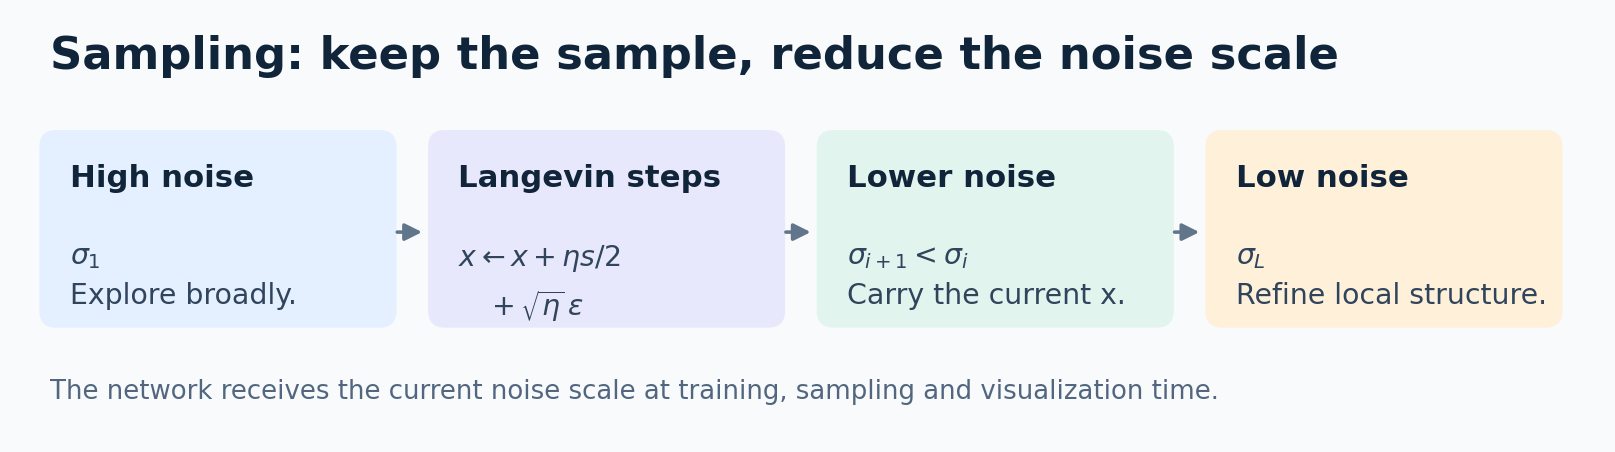

**Takeaway.** Do not restart from independent noise at each level.

### Conditioning on noise

A model can receive either a level index or the noise value. The convention must agree everywhere. The 2D implementation in Part 2 uses the **actual sigma value**. This illustrative image block uses a **discrete level embedding** instead.

In [1]:
import torch
from torch import nn

class ConditionedResnetBlock(nn.Module):
    def __init__(self, dim: int, num_embeddings: int) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(dim, dim, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(dim, dim, kernel_size=1),
        )
        self.dim = dim
        self.embedding = nn.Embedding(num_embeddings=num_embeddings, embedding_dim=dim)

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        time_embed = self.embedding(y).view(-1, self.dim, 1, 1)
        return x + self.block(x + time_embed)

## Takeaways

1. The score is a gradient with respect to the input.
2. Gaussian corruption supplies the target $-\epsilon/\sigma$.
3. Langevin sampling needs both drift and noise.
4. A shared, conditioned model learns several noise scales; sampling visits them from large to small.

**Next:** [inspect the two-dimensional experiments](ncsn.ipynb).